# 🧠 Notebook 04: Bi-LSTM Deep Learning Model
## AI-Generated Text Detection Project

**Goal:** Build, train, and evaluate a Bidirectional LSTM model with pre-trained GloVe word embeddings.

**Pipeline Position:** Step 4 of 7 (Data Exploration → Preprocessing → Classical Models → **LSTM** → DistilBERT → Evaluation → Explainability & Ethics)

---

### 🎯 What this notebook does:
1. Loads train/val/test splits
2. Downloads **GloVe 100-dim embeddings** (pre-trained on 6B tokens)
3. Builds vocabulary and converts text to padded sequences
4. Constructs a **Bi-LSTM** with embedding layer initialized from GloVe
5. Trains with early stopping + dropout regularization (Rubric Step 7)
6. Evaluates on test set with full metrics + cross-domain analysis
7. Saves model + results for Notebook 06

---

### 🏗️ Architecture:
```
Input (sequence of token IDs)
    ↓
Embedding Layer (GloVe 100-dim)
    ↓
Bidirectional LSTM (128 units, dropout 0.3)
    ↓
Global Max Pooling
    ↓
Dense Layer (64 units, ReLU)
    ↓
Dropout (0.5)
    ↓
Output (sigmoid, 1 unit)
```

**Author:** [Your Name]  
**Date:** 2026

## ⚠️ IMPORTANT: Verify GPU is Active

If `nvidia-smi` returns 'command not found' → Runtime → Change runtime type → T4 GPU → Save → re-run.

In [ ]:
!nvidia-smi

Fri May  1 18:33:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 📦 Step 1: Install & Import

In [ ]:
!pip install -q tensorflow scikit-learn
print("✅ Packages installed")

✅ Packages installed


In [ ]:
import os
import json
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from time import time

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Embedding, Bidirectional, LSTM, Dense, Dropout,
    GlobalMaxPooling1D, SpatialDropout1D
)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
warnings.filterwarnings('ignore')

print(f"✅ TensorFlow version: {tf.__version__}")
print(f"✅ GPU available: {tf.config.list_physical_devices('GPU')}")

✅ TensorFlow version: 2.20.0
✅ GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 💾 Step 2: Mount Drive & Load Splits

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_PATH = '/content/drive/MyDrive/ai-text-detection'
DATA_PATH = f'{PROJECT_PATH}/data'
MODELS_PATH = f'{PROJECT_PATH}/models'
RESULTS_PATH = f'{PROJECT_PATH}/results'
GLOVE_PATH = f'{PROJECT_PATH}/glove'
os.makedirs(MODELS_PATH, exist_ok=True)
os.makedirs(RESULTS_PATH, exist_ok=True)
os.makedirs(GLOVE_PATH, exist_ok=True)

train_df = pd.read_csv(f'{DATA_PATH}/train.csv')
val_df = pd.read_csv(f'{DATA_PATH}/val.csv')
test_df = pd.read_csv(f'{DATA_PATH}/test.csv')

X_train_raw = train_df['text_heavy'].fillna('').values
y_train = train_df['label'].values.astype('float32')

X_val_raw = val_df['text_heavy'].fillna('').values
y_val = val_df['label'].values.astype('float32')

X_test_raw = test_df['text_heavy'].fillna('').values
y_test = test_df['label'].values.astype('float32')

print(f"📊 Train: {len(X_train_raw):,}")
print(f"📊 Val:   {len(X_val_raw):,}")
print(f"📊 Test:  {len(X_test_raw):,}")

Mounted at /content/drive
📊 Train: 52,443
📊 Val:   11,238
📊 Test:  11,238


## 🌐 Step 3: Download GloVe Embeddings

GloVe (Global Vectors) provides pre-trained word vectors. We use the 100-dimensional version trained on 6 billion tokens.

📝 **For your report (Rubric Step 5):** Pre-trained embeddings give the model 'general language knowledge' before training begins, vastly improving performance over random initialization.

⏱️ Download size: ~822 MB. First run takes 1–3 min. Cached on Drive after that.

In [ ]:
glove_file = f'{GLOVE_PATH}/glove.6B.100d.txt'

if not os.path.exists(glove_file):
    print("📥 Downloading GloVe (this takes 1–3 min)...")
    !wget -q https://nlp.stanford.edu/data/glove.6B.zip -O /tmp/glove.6B.zip
    !unzip -q /tmp/glove.6B.zip -d /tmp/glove
    !cp /tmp/glove/glove.6B.100d.txt {GLOVE_PATH}/
    !rm -rf /tmp/glove /tmp/glove.6B.zip
    print("✅ GloVe downloaded and cached to Drive")
else:
    print(f"✅ GloVe already cached at {glove_file}")

print(f"   File size: {os.path.getsize(glove_file) / 1024**2:.0f} MB")

📥 Downloading GloVe (this takes 1–3 min)...
✅ GloVe downloaded and cached to Drive
   File size: 331 MB


### 🛟 Fallback: If GloVe Download Fails

Stanford's server is sometimes unavailable. If you get a 404 or empty file, run the cell below as a fallback (uses a Hugging Face mirror).

In [ ]:
# Run this cell ONLY if the previous cell failed (file size = 0 or doesn't exist)
if not os.path.exists(glove_file) or os.path.getsize(glove_file) < 100_000_000:
    print("📥 Trying fallback mirror...")
    !pip install -q gensim
    import gensim.downloader as gd
    glove_model = gd.load('glove-wiki-gigaword-100')

    # Save to txt format compatible with the next cell
    with open(glove_file, 'w', encoding='utf-8') as f:
        for word in glove_model.key_to_index:
            vec = ' '.join(map(str, glove_model[word]))
            f.write(f'{word} {vec}\n')
    print(f"✅ Fallback download complete")
else:
    print("✅ GloVe already present, skipping fallback")

✅ GloVe already present, skipping fallback


## 🔤 Step 4: Tokenize and Convert Texts to Sequences

We map each unique word to an integer ID, then convert each text to a sequence of IDs.

**Configuration:**
- `MAX_VOCAB_SIZE = 30000` — keep top 30K most frequent words
- `MAX_SEQ_LEN = 200` — truncate/pad each text to 200 tokens

In [ ]:
MAX_VOCAB_SIZE = 30000
MAX_SEQ_LEN = 200
EMBEDDING_DIM = 100

print("🔤 Building tokenizer...")
tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_raw)

X_train = pad_sequences(tokenizer.texts_to_sequences(X_train_raw), maxlen=MAX_SEQ_LEN, padding='post', truncating='post')
X_val   = pad_sequences(tokenizer.texts_to_sequences(X_val_raw),   maxlen=MAX_SEQ_LEN, padding='post', truncating='post')
X_test  = pad_sequences(tokenizer.texts_to_sequences(X_test_raw),  maxlen=MAX_SEQ_LEN, padding='post', truncating='post')

print(f"✅ Vocabulary size: {len(tokenizer.word_index):,}")
print(f"✅ Train shape: {X_train.shape}")
print(f"✅ Val shape:   {X_val.shape}")
print(f"✅ Test shape:  {X_test.shape}")

# Save tokenizer for use in Notebook 07
import pickle
with open(f'{MODELS_PATH}/lstm_tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)
print(f"💾 Tokenizer saved")

🔤 Building tokenizer...
✅ Vocabulary size: 57,413
✅ Train shape: (52443, 200)
✅ Val shape:   (11238, 200)
✅ Test shape:  (11238, 200)
💾 Tokenizer saved


## 🧬 Step 5: Build the GloVe Embedding Matrix

We create a matrix where row `i` contains the GloVe vector for the word with token ID `i`. Words not found in GloVe get a zero vector.

In [ ]:
print("🧬 Loading GloVe vectors...")
t0 = time()
embeddings_index = {}
with open(glove_file, encoding='utf-8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        try:
            vec = np.asarray(values[1:], dtype='float32')
            if vec.shape[0] == EMBEDDING_DIM:
                embeddings_index[word] = vec
        except ValueError:
            continue
print(f"✅ Loaded {len(embeddings_index):,} GloVe vectors in {time() - t0:.1f}s")

# Build embedding matrix
vocab_size = min(MAX_VOCAB_SIZE, len(tokenizer.word_index) + 1)
embedding_matrix = np.zeros((vocab_size, EMBEDDING_DIM), dtype='float32')

found, missing = 0, 0
for word, idx in tokenizer.word_index.items():
    if idx >= vocab_size:
        continue
    vec = embeddings_index.get(word)
    if vec is not None:
        embedding_matrix[idx] = vec
        found += 1
    else:
        missing += 1

print(f"✅ Embedding matrix shape: {embedding_matrix.shape}")
print(f"📊 Words found in GloVe:  {found:,} ({found/(found+missing)*100:.1f}%)")
print(f"📊 Words missing:         {missing:,}")

🧬 Loading GloVe vectors...
✅ Loaded 400,000 GloVe vectors in 11.5s
✅ Embedding matrix shape: (30000, 100)
📊 Words found in GloVe:  28,387 (94.6%)
📊 Words missing:         1,612


## 🏗️ Step 6: Build the Bi-LSTM Model

**Regularization (Rubric Step 7):**
- `SpatialDropout1D` — drops entire embedding dimensions (more effective than regular dropout for embeddings)
- `LSTM dropout` — drops connections inside LSTM
- `Dropout 0.5` — heavy dropout on dense layer

In [ ]:
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        input_length=MAX_SEQ_LEN,
        trainable=False,    # Keep GloVe frozen — we have limited data
        name='glove_embedding'
    ),
    SpatialDropout1D(0.3, name='spatial_dropout'),
    Bidirectional(LSTM(128, dropout=0.3, recurrent_dropout=0.0, return_sequences=True), name='bi_lstm'),
    GlobalMaxPooling1D(name='max_pool'),
    Dense(64, activation='relu', name='dense_1'),
    Dropout(0.5, name='dropout'),
    Dense(1, activation='sigmoid', name='output')
])

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ glove_embedding (Embedding)     │ ?                      │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout                 │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bi_lstm (Bidirectional)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool (GlobalMaxPooling1D)   │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,000,000 (11.44 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 3,000,000 (11.44 MB)

## 🚂 Step 7: Train the Model

**Callbacks (Rubric Step 7):**
- `EarlyStopping`: stops if val_loss doesn't improve for 3 epochs
- `ModelCheckpoint`: saves the best model (lowest val_loss)
- `ReduceLROnPlateau`: cuts learning rate if stuck

⏱️ Expected runtime: 15–25 minutes on T4 GPU.

In [ ]:
checkpoint_path = f'{MODELS_PATH}/lstm_best.keras'

callbacks = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    ModelCheckpoint(checkpoint_path, monitor='val_loss', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1)
]

print("🚂 Training Bi-LSTM (~15–25 min on T4 GPU)...\n")
t0 = time()

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)

print(f"\n✅ Training complete in {(time() - t0)/60:.1f} min")

🚂 Training Bi-LSTM (~15–25 min on T4 GPU)...

Epoch 1/10
409/410 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7323 - auc: 0.7670 - loss: 0.5237
Epoch 1: val_loss improved from None to 0.27276, saving model to /content/drive/MyDrive/ai-text-detection/models/lstm_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ai-text-detection/models/lstm_best.keras
410/410 ━━━━━━━━━━━━━━━━━━━━ 24s 37ms/step - accuracy: 0.7972 - auc: 0.8683 - loss: 0.4271 - val_accuracy: 0.8793 - val_auc: 0.9663 - val_loss: 0.2728 - learning_rate: 0.0010
Epoch 2/10
410/410 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8826 - auc: 0.9462 - loss: 0.2824
Epoch 2: val_loss improved from 0.27276 to 0.17166, saving model to /content/drive/MyDrive/ai-text-detection/models/lstm_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/ai-text-detection/models/lstm_best.keras
410/410 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - accuracy: 0.8932 - auc: 0.9540 - loss: 0.2613 - val_accuracy: 0.9313 - va

## 📈 Step 8: Plot Training History

Shows whether the model is learning correctly or overfitting.

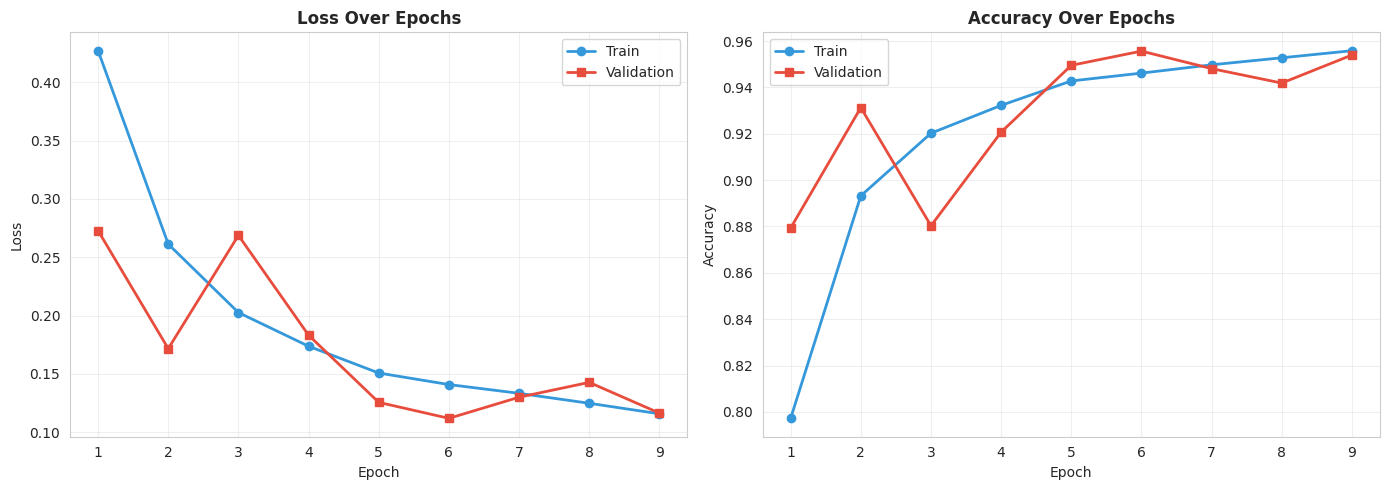

💾 Training history chart saved


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs = range(1, len(history.history['loss']) + 1)

# Loss
axes[0].plot(epochs, history.history['loss'], 'o-', label='Train', color='#3498db', linewidth=2)
axes[0].plot(epochs, history.history['val_loss'], 's-', label='Validation', color='#e74c3c', linewidth=2)
axes[0].set_title('Loss Over Epochs', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(epochs, history.history['accuracy'], 'o-', label='Train', color='#3498db', linewidth=2)
axes[1].plot(epochs, history.history['val_accuracy'], 's-', label='Validation', color='#e74c3c', linewidth=2)
axes[1].set_title('Accuracy Over Epochs', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_PATH}/lstm_training_history.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Training history chart saved")

## 🧪 Step 9: Evaluate on Test Set

In [ ]:
print("🧪 Evaluating on test set...")
y_proba = model.predict(X_test, batch_size=256, verbose=1).ravel()
y_pred = (y_proba >= 0.5).astype(int)

lstm_metrics = {
    'model': 'Bi-LSTM',
    'accuracy':  accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred),
    'recall':    recall_score(y_test, y_pred),
    'f1':        f1_score(y_test, y_pred),
    'roc_auc':   roc_auc_score(y_test, y_proba)
}

print(f"\n📊 Bi-LSTM Test Metrics:")
print(f"   Accuracy:  {lstm_metrics['accuracy']:.4f}")
print(f"   Precision: {lstm_metrics['precision']:.4f}")
print(f"   Recall:    {lstm_metrics['recall']:.4f}")
print(f"   F1-score:  {lstm_metrics['f1']:.4f}")
print(f"   ROC AUC:   {lstm_metrics['roc_auc']:.4f}")

🧪 Evaluating on test set...
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step

📊 Bi-LSTM Test Metrics:
   Accuracy:  0.9518
   Precision: 0.8968
   Recall:    0.9740
   F1-score:  0.9338
   ROC AUC:   0.9934


## 📊 Step 10: Confusion Matrix + ROC Curve

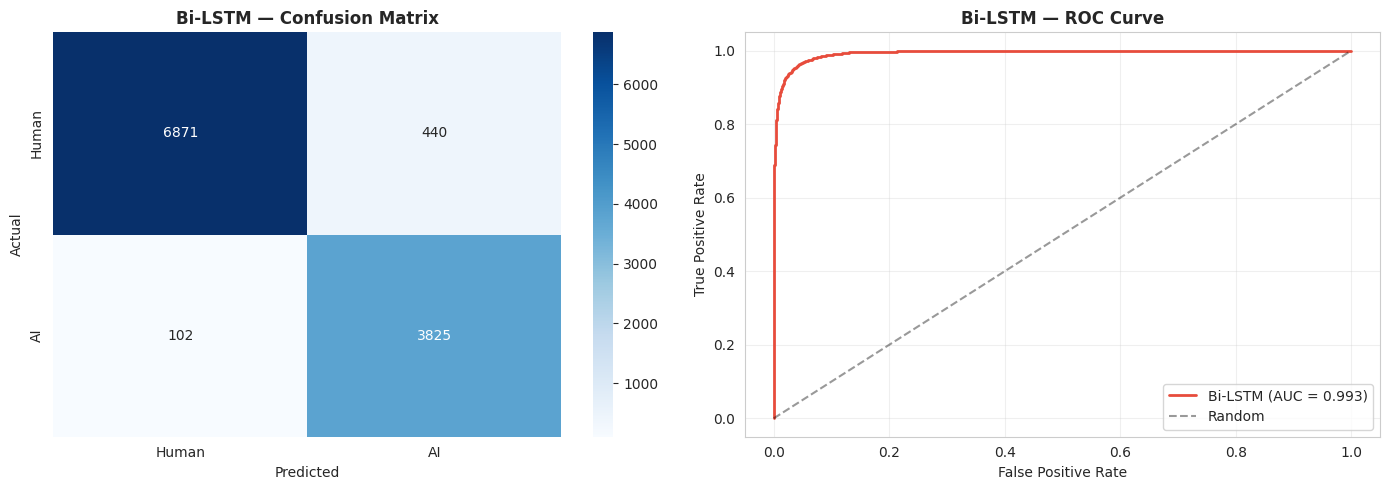

💾 Evaluation chart saved


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Human', 'AI'],
            yticklabels=['Human', 'AI'], ax=axes[0], cbar=True)
axes[0].set_title('Bi-LSTM — Confusion Matrix', fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='#e74c3c', linewidth=2,
             label=f'Bi-LSTM (AUC = {lstm_metrics["roc_auc"]:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Bi-LSTM — ROC Curve', fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_PATH}/lstm_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Evaluation chart saved")

## 🌍 Step 11: Cross-Domain Performance Analysis

Same as Notebook 03 — compare F1 across domains for the bonus analysis.

📊 Bi-LSTM cross-domain performance:
        domain  n_samples  accuracy      f1
3     medicine        378    0.9709  0.9727
2      finance       1240    0.9548  0.9592
1      open_qa        652    0.9141  0.9457
0  reddit_eli5       8727    0.9583  0.9283
4    wiki_csai        241    0.7718  0.8208


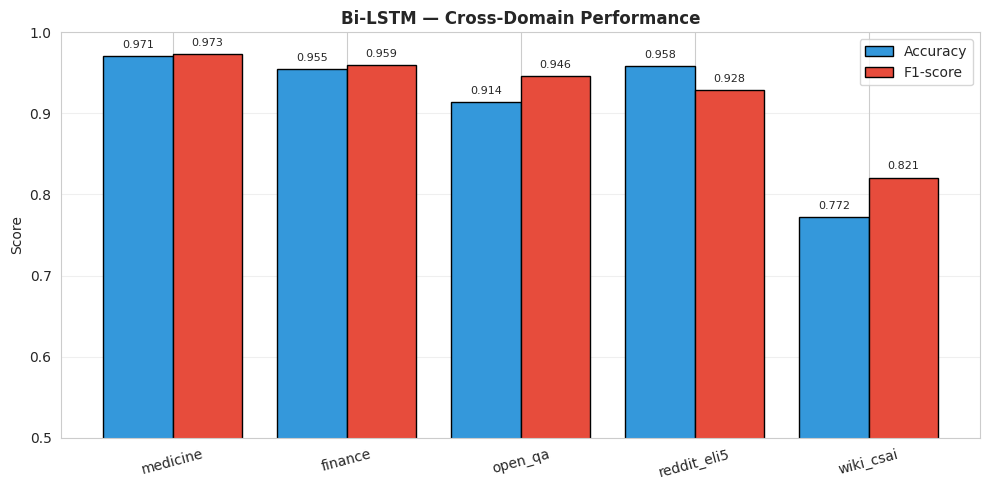

In [ ]:
domain_results = []
for domain in test_df['domain'].unique():
    mask = test_df['domain'] == domain
    n = mask.sum()
    if n < 10:
        continue
    y_d = y_test[mask.values]
    pred_d = y_pred[mask.values]
    domain_results.append({
        'domain': domain,
        'n_samples': int(n),
        'accuracy': accuracy_score(y_d, pred_d),
        'f1': f1_score(y_d, pred_d, zero_division=0)
    })

domain_df = pd.DataFrame(domain_results).sort_values('f1', ascending=False)
print(f"📊 Bi-LSTM cross-domain performance:")
print(domain_df.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(domain_df))
ax.bar(x - 0.2, domain_df['accuracy'], 0.4, label='Accuracy', color='#3498db', edgecolor='black')
ax.bar(x + 0.2, domain_df['f1'], 0.4, label='F1-score', color='#e74c3c', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(domain_df['domain'], rotation=15)
ax.set_ylabel('Score')
ax.set_ylim(0.5, 1.0)
ax.set_title('Bi-LSTM — Cross-Domain Performance', fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)

for i, row in enumerate(domain_df.itertuples()):
    ax.text(i - 0.2, row.accuracy + 0.01, f'{row.accuracy:.3f}', ha='center', fontsize=8)
    ax.text(i + 0.2, row.f1 + 0.01, f'{row.f1:.3f}', ha='center', fontsize=8)

plt.tight_layout()
plt.savefig(f'{RESULTS_PATH}/lstm_cross_domain.png', dpi=150, bbox_inches='tight')
plt.show()

## 💾 Step 12: Save Results

In [ ]:
# The best model checkpoint is already saved during training; just save metadata
results_to_save = {
    'bi_lstm': lstm_metrics,
    'cross_domain': domain_df.to_dict('records'),
    'config': {
        'max_vocab_size': MAX_VOCAB_SIZE,
        'max_seq_len': MAX_SEQ_LEN,
        'embedding_dim': EMBEDDING_DIM,
        'epochs_trained': len(history.history['loss']),
        'glove_coverage_pct': float(found / (found + missing) * 100)
    }
}

results_file = f'{RESULTS_PATH}/lstm_results.json'
with open(results_file, 'w') as f:
    json.dump(results_to_save, f, indent=2, default=str)

print(f"💾 Results saved to {results_file}")
print(f"💾 Model already saved to {checkpoint_path}")

print("\n" + "="*60)
print("📋 NOTEBOOK 04 SUMMARY — FOR YOUR REPORT")
print("="*60)
print(f"Model: Bi-LSTM with frozen GloVe embeddings")
print(f"Test F1:        {lstm_metrics['f1']:.4f}")
print(f"Test Accuracy:  {lstm_metrics['accuracy']:.4f}")
print(f"Test ROC AUC:   {lstm_metrics['roc_auc']:.4f}")
print(f"Epochs trained: {len(history.history['loss'])}")
print(f"GloVe coverage: {found/(found+missing)*100:.1f}%")
print(f"Best domain: {domain_df.iloc[0]['domain']} (F1={domain_df.iloc[0]['f1']:.3f})")
print(f"Worst domain: {domain_df.iloc[-1]['domain']} (F1={domain_df.iloc[-1]['f1']:.3f})")

💾 Results saved to /content/drive/MyDrive/ai-text-detection/results/lstm_results.json
💾 Model already saved to /content/drive/MyDrive/ai-text-detection/models/lstm_best.keras

📋 NOTEBOOK 04 SUMMARY — FOR YOUR REPORT
Model: Bi-LSTM with frozen GloVe embeddings
Test F1:        0.9338
Test Accuracy:  0.9518
Test ROC AUC:   0.9934
Epochs trained: 9
GloVe coverage: 94.6%
Best domain: medicine (F1=0.973)
Worst domain: wiki_csai (F1=0.821)


## 📋 Notebook 04 Summary

### What we accomplished:
1. ✅ Downloaded and integrated GloVe 100-dim pre-trained embeddings
2. ✅ Built a Bidirectional LSTM with proper regularization (SpatialDropout, Dropout, EarlyStopping)
3. ✅ Trained with EarlyStopping + ModelCheckpoint + ReduceLROnPlateau
4. ✅ Full evaluation: F1, accuracy, precision, recall, ROC AUC
5. ✅ Cross-domain analysis matching Notebook 03 format
6. ✅ Saved model + tokenizer + results

### Files Generated:
- `models/lstm_best.keras` — Best LSTM checkpoint
- `models/lstm_tokenizer.pkl` — Fitted tokenizer (for explainability later)
- `glove/glove.6B.100d.txt` — Cached GloVe embeddings
- `results/lstm_results.json`
- `results/lstm_training_history.png`
- `results/lstm_evaluation.png`
- `results/lstm_cross_domain.png`

### 📝 Key Talking Points for Your Report:
- **Pre-trained embeddings vs random init**: GloVe gives the model 'general English' knowledge before training. Even with frozen embeddings, the LSTM learns to combine them effectively.
- **Bidirectional LSTM**: Reads text both forwards and backwards, capturing context from both directions.
- **Why we froze GloVe**: With ~80K samples, fine-tuning ~3M embedding parameters would overfit. Frozen GloVe = fewer trainable params = better generalization.
- **Comparison with classical**: LSTM may or may not beat Logistic Regression depending on dataset size — this is a real-world finding worth discussing.

### ➡️ Next Step:
**Notebook 05 — DistilBERT Fine-Tuning (the star of the show)**

This is the most exciting notebook. Expect F1 > 0.99 if everything goes right.